# <font color="blue">Detección de anomalías cardiacas en señales ECG con Autoencoder</font>
# <font color="red">Alfredo Díaz Claros</font>


## Objetivo de la práctica

En la práctica anterior descargamos un **ECG real** del registro 23 de la base LTAFDB (PhysioNet) y aprendimos a leer sus latidos y anotaciones. Ahora usaremos esos mismos datos para entrenar un **autoencoder** que detecte latidos anómalos.

### ¿Cómo funciona la idea?

1. Un autoencoder aprende a **comprimir y reconstruir** señales. Su error de reconstrucción es pequeño para los datos que se parecen a los que vio durante el entrenamiento.
2. Entrenamos el modelo **solo con latidos normales**.
3. Cuando llega un latido distinto a lo aprendido (anómalo), el modelo no lo reconstruye bien y su **error sube**.
4. Si el error supera un **umbral**, el latido se clasifica como anómalo.

La ventaja de este enfoque es que **no necesita muchos ejemplos anómalos** para entrenar. En la práctica, los latidos anómalos suelen ser raros, y el modelo solo requiere datos normales.

> **Nota:** en esta práctica usamos las anotaciones de la base de datos para comprobar los resultados. El modelo nunca ve las etiquetas anómalas durante el entrenamiento.

## Parte 1. Preparar el entorno y los datos

### Paso 1. Instalar `wfdb`

TensorFlow ya viene instalado en Google Colab. Solo necesitamos instalar `wfdb`, la biblioteca para leer archivos de PhysioNet.

In [ ]:
!pip install wfdb -q

### Paso 2. Descargar el registro 23 de PhysioNet

Descargamos los tres archivos del registro: la señal (`.dat`), la cabecera (`.hea`) y las anotaciones de los latidos (`.atr`).

In [ ]:
!mkdir -p ecg-data

!wget -q https://physionet.org/files/ltafdb/1.0.0/23.dat -P ecg-data/
!wget -q https://physionet.org/files/ltafdb/1.0.0/23.hea -P ecg-data/
!wget -q https://physionet.org/files/ltafdb/1.0.0/23.atr -P ecg-data/

### Paso 3. Importar bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import tensorflow as tf
from tensorflow.keras import Model, Input, layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, auc)
import seaborn as sns

np.random.seed(21)
tf.random.set_seed(21)

## Parte 2. Preparar los datos: segmentar los latidos

El autoencoder necesita ejemplos de **longitud fija**. Por eso no usaremos la señal completa, sino **un segmento por cada latido**.

### Paso 4. Leer la señal y las anotaciones

Usamos el canal 0 de la señal y las anotaciones `.atr`, que indican la posición (`sample`) de cada latido y su tipo (`symbol`).

In [ ]:
record_path = 'ecg-data/23'

record = wfdb.rdrecord(record_path)
ann = wfdb.rdann(record_path, 'atr')

signal = record.p_signal[:, 0]
fs = record.fs

print("Frecuencia de muestreo (fs):", fs, "Hz")
print("Número de muestras:", len(signal))
print("Número de anotaciones:", len(ann.sample))

Frecuencia de muestreo (fs): 128 Hz
Número de muestras: 11819520
Número de anotaciones: 102494


### Paso 5. Definir qué símbolos son latidos

La base de datos también contiene marcas que **no son latidos**, como cambios de ritmo (`+`), artefactos (`~`) o inicios de episodio. Solo nos interesan los símbolos que corresponden a latidos.

In [ ]:
# Símbolos que corresponden a latidos (N = normal, V = ventricular prematuro, A = auricular prematuro, etc.)
BEAT_SYMBOLS = list('NLRBAaJSVrFejnE/fQ')

# Conteo de los símbolos presentes en el registro
pd.Series(ann.symbol).value_counts().head(15)

,count
N,81870
A,15677
+,2537
V,2407
"""",3


### Paso 6. Recortar un segmento de 140 muestras alrededor de cada latido

Cada latido se recorta desde **60 muestras antes** de la onda R hasta **80 muestras después**. Así obtenemos segmentos de **140 valores**, la misma longitud que el conjunto ECG5000 del notebook original.

La etiqueta se asigna así:

- **0 = normal** si el símbolo es `N`.
- **1 = anómalo** para el resto de latidos (por ejemplo, `V` o `A`).

> **Decisión de diseño:** en un análisis clínico real, algunos latidos como `L` o `R` (bloqueos de rama) también podrían considerarse anómalos. Aquí usamos una definición sencilla para facilitar la comprensión.

In [ ]:
VENTANA_ANTES = 60
VENTANA_DESPUES = 80
LONGITUD = VENTANA_ANTES + VENTANA_DESPUES  # 140 muestras por latido

beats, labels, positions = [], [], []

for pos, sym in zip(ann.sample, ann.symbol):
    if sym not in BEAT_SYMBOLS:
        continue
    ini = pos - VENTANA_ANTES
    fin = pos + VENTANA_DESPUES
    if ini < 0 or fin > len(signal):
        continue  # Se descartan latidos en los bordes del registro
    beats.append(signal[ini:fin])
    labels.append(0 if sym == 'N' else 1)   # 0 = normal, 1 = anómalo
    positions.append(pos)

X = np.array(beats, dtype=np.float32)
y = np.array(labels)
positions = np.array(positions)

print("Forma de los datos (latidos x muestras):", X.shape)
print("Latidos normales (0):", np.sum(y == 0))
print("Latidos anómalos (1):", np.sum(y == 1))
print("Porcentaje de anómalos: {:.2f} %".format(100 * np.mean(y == 1)))

Forma de los datos (latidos x muestras): (99954, 140)
Latidos normales (0): 81870
Latidos anómalos (1): 18084
Porcentaje de anómalos: 18.09 %


### Paso 7. Visualizar latidos normales y anómalos

Comparamos visualmente algunos latidos de cada clase. Los anómalos deberían verse distintos de los normales.

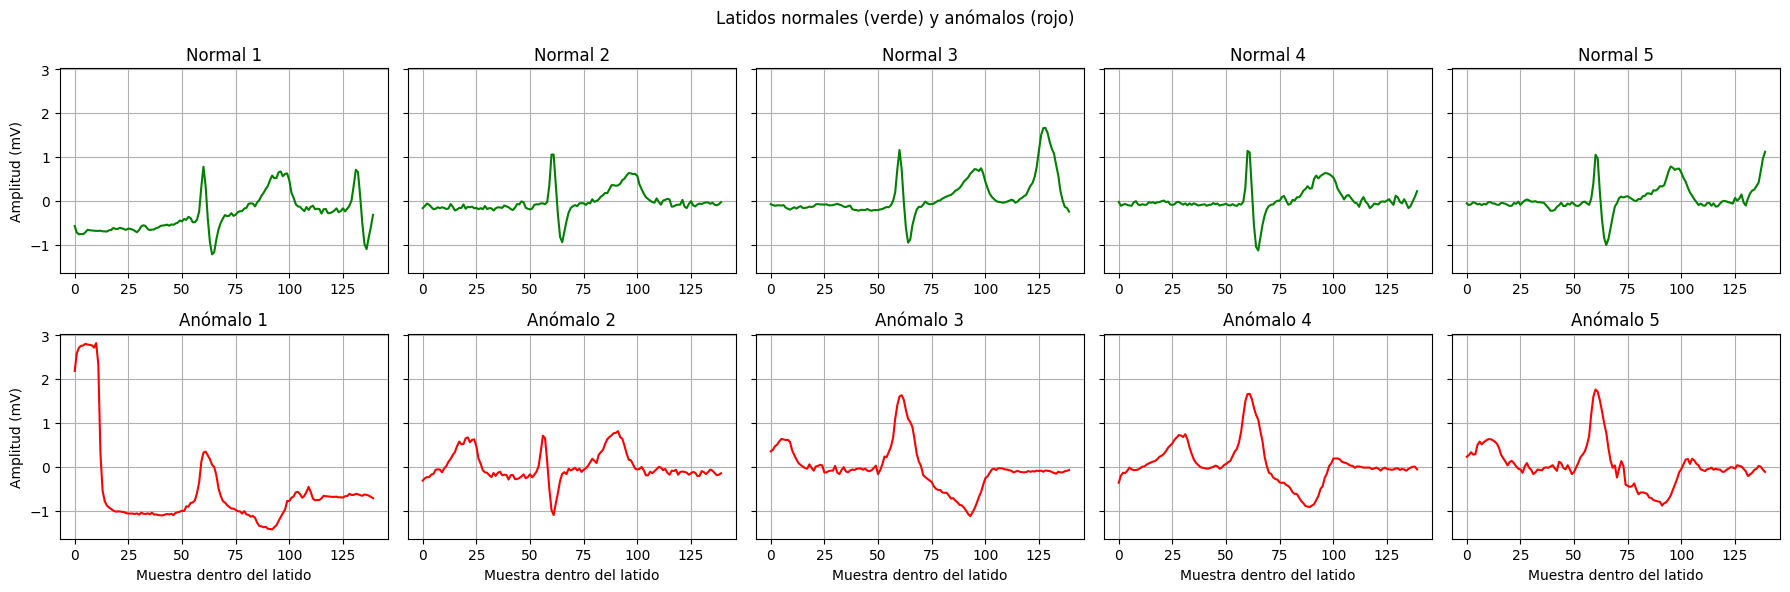

In [ ]:
normales = X[y == 0][:5]
anomalos = X[y == 1][:5]

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=True)

for i in range(5):
    axes[0, i].plot(normales[i], color='green')
    axes[0, i].set_title(f"Normal {i+1}")
    axes[0, i].grid(True)

    if i < len(anomalos):
        axes[1, i].plot(anomalos[i], color='red')
        axes[1, i].set_title(f"Anómalo {i+1}")
    axes[1, i].grid(True)

for ax in axes[:, 0]:
    ax.set_ylabel("Amplitud (mV)")
for ax in axes[1, :]:
    ax.set_xlabel("Muestra dentro del latido")

plt.suptitle("Latidos normales (verde) y anómalos (rojo)")
plt.tight_layout()
plt.show()

### Paso 8. Dividir los datos en entrenamiento y prueba

Usamos el 80 % para entrenar y el 20 % para probar. La opción `stratify=y` mantiene la misma proporción de normales y anómalos en ambos conjuntos.

In [ ]:
train_data, test_data, train_labels, test_labels = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y)

print("Entrenamiento:", train_data.shape, "| Prueba:", test_data.shape)

Entrenamiento: (79963, 140) | Prueba: (19991, 140)


### Paso 9. Normalizar los datos a [0, 1]

El ajuste del normalizador (`fit`) se hace **solo con los latidos normales de entrenamiento**. Así evitamos que información de la prueba influya en el entrenamiento.

La capa de salida del autoencoder usa `sigmoid`, que produce valores entre 0 y 1. Por eso los datos deben estar en ese rango.

In [ ]:
normal_train_raw = train_data[train_labels == 0]

scaler = MinMaxScaler()
scaler.fit(normal_train_raw)

train_data_s = scaler.transform(train_data).astype(np.float32)
test_data_s = scaler.transform(test_data).astype(np.float32)
X_all_s = scaler.transform(X).astype(np.float32)

# Separar normales y anómalos
normal_train_data = train_data_s[train_labels == 0]
normal_test_data = test_data_s[test_labels == 0]
anomalous_test_data = test_data_s[test_labels == 1]

print("Normales para entrenar:", len(normal_train_data))
print("Normales para prueba:  ", len(normal_test_data))
print("Anómalos para prueba:  ", len(anomalous_test_data))

Normales para entrenar: 65496
Normales para prueba:   16374
Anómalos para prueba:   3617


## Parte 3. Construir y entrenar el autoencoder

### Paso 10. Definir la arquitectura

- **Encoder:** reduce los 140 valores a una representación de 8 números (cuello de botella).
- **Decoder:** reconstruye los 140 valores a partir de esos 8 números.

El cuello de botella obliga al modelo a aprender solo los rasgos principales de un latido normal.

In [ ]:
input_layer = Input(shape=(LONGITUD,))

# --- Encoder ---
encoded = layers.Dense(32, activation="relu")(input_layer)
encoded = layers.Dense(16, activation="relu")(encoded)
encoded = layers.Dense(8, activation="relu")(encoded)

# --- Decoder ---
decoded = layers.Dense(16, activation="relu")(encoded)
decoded = layers.Dense(32, activation="relu")(decoded)
decoded = layers.Dense(LONGITUD, activation="sigmoid")(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 140)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 140)            │         4,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,484 (40.95 KB)

 Trainable params: 10,484 (40.95 KB)

 Non-trainable params: 0 (0.00 B)

### Paso 11. Compilar el modelo

- **Optimizador `adam`:** ajusta los pesos durante el entrenamiento.
- **Pérdida `mse`:** mide la diferencia cuadrática entre el latido original y su reconstrucción.

In [ ]:
autoencoder.compile(optimizer='adam', loss='mse')

### Paso 12. Entrenar solo con latidos normales

Observe que el modelo recibe **solo latidos normales** como entrada y como salida esperada. Los anómalos no se usan en el entrenamiento.

In [ ]:
history = autoencoder.fit(
    normal_train_data, normal_train_data,
    epochs=20,
    batch_size=512,
    validation_data=(normal_test_data, normal_test_data),
    shuffle=True,
    verbose=1)

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 0.0036 - val_loss: 0.0015
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 8.9834e-04
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.5494e-04 - val_loss: 8.1446e-04
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.8247e-04 - val_loss: 7.5911e-04
Epoch 9/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.4895e-04 - val_loss: 7.3804e-04
Epoch 10/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.3065e-04 - val_loss: 7.1905e-04
Epoch 11/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.1120e-04 - val_loss: 6.9992e-04
Epoch 1

### Paso 13. Revisar la curva de pérdida

Si la pérdida de validación se mantiene cerca de la de entrenamiento, el modelo generaliza bien. Si la validación sube mientras el entrenamiento baja, hay sobreajuste.

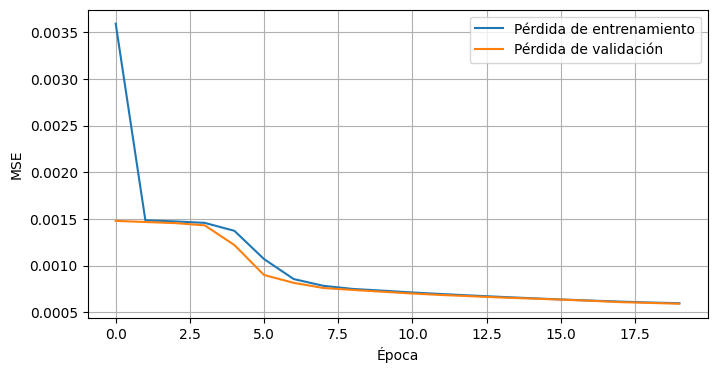

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Pérdida de entrenamiento")
plt.plot(history.history["val_loss"], label="Pérdida de validación")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()

## Parte 4. Detección de anomalías

### Paso 14. Visualizar la reconstrucción de un latido normal

Se muestra el latido original (azul), su reconstrucción (rojo) y el error entre ambos (sombreado).

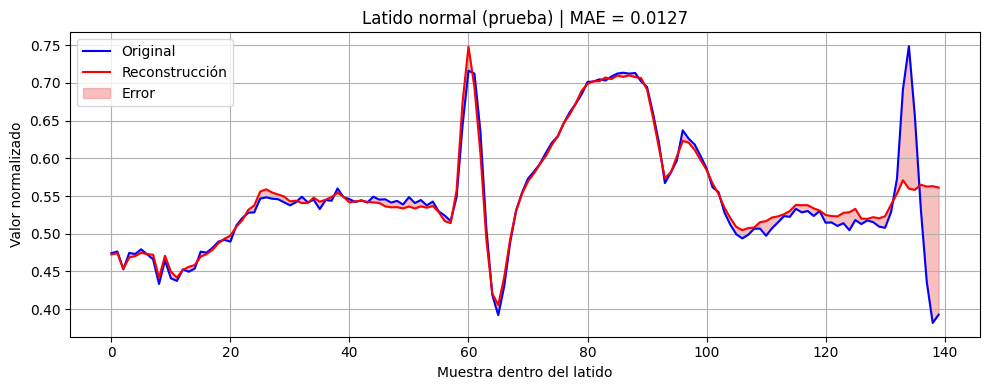

In [ ]:
def graficar_reconstruccion(latido, titulo):
    reconstruccion = autoencoder(latido[np.newaxis, :]).numpy()[0]
    error = np.abs(latido - reconstruccion)

    plt.figure(figsize=(10, 4))
    plt.plot(latido, color='blue', label='Original')
    plt.plot(reconstruccion, color='red', label='Reconstrucción')
    plt.fill_between(np.arange(LONGITUD), reconstruccion, latido,
                     color='lightcoral', alpha=0.5, label='Error')
    plt.title(f"{titulo} | MAE = {error.mean():.4f}")
    plt.xlabel("Muestra dentro del latido")
    plt.ylabel("Valor normalizado")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

graficar_reconstruccion(normal_test_data[0], "Latido normal (prueba)")

### Paso 15. Visualizar la reconstrucción de un latido anómalo

Un latido anómalo suele reconstruirse peor, por lo que su error es más grande.

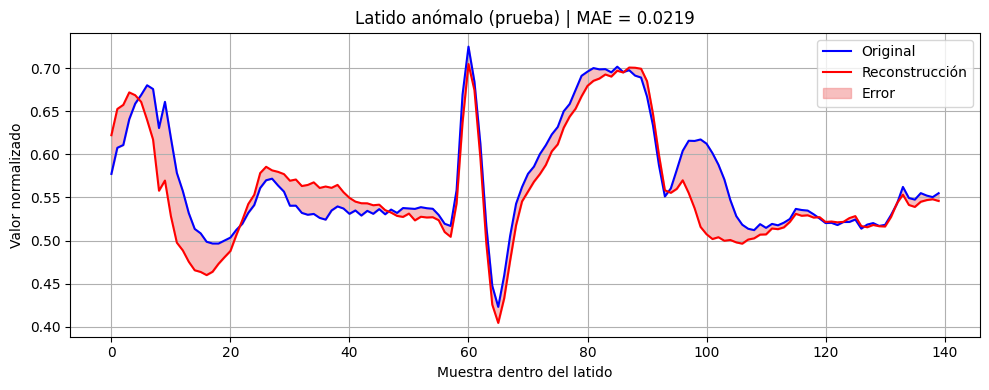

In [ ]:
graficar_reconstruccion(anomalous_test_data[0], "Latido anómalo (prueba)")

### Paso 16. Calcular el error de reconstrucción en los latidos normales de entrenamiento

Usamos el **MAE** (error absoluto medio) de cada latido como medida de anomalía. Con los latidos normales de entrenamiento construimos la distribución de referencia.

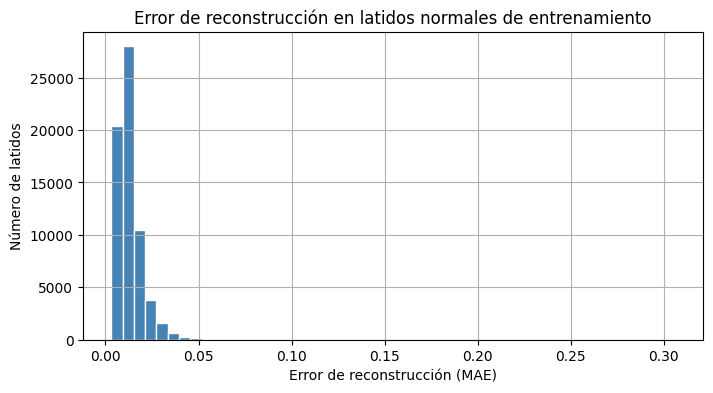

In [ ]:
reconstructions_train = autoencoder.predict(normal_train_data, verbose=0)
train_loss = tf.keras.losses.mae(reconstructions_train, normal_train_data).numpy()

plt.figure(figsize=(8, 4))
plt.hist(train_loss, bins=50, color='steelblue', edgecolor='white')
plt.xlabel("Error de reconstrucción (MAE)")
plt.ylabel("Número de latidos")
plt.title("Error de reconstrucción en latidos normales de entrenamiento")
plt.grid(True)
plt.show()

### Paso 17. Definir el umbral

El umbral se fija como **la media más una desviación estándar** del error de los latidos normales de entrenamiento. Todo latido con error por encima de ese valor se considerará anómalo.

Este umbral es un punto de partida. Más adelante probaremos otra forma de elegirlo.

In [ ]:
threshold = np.mean(train_loss) + np.std(train_loss)
print("Umbral de anomalía (media + 1 desviación estándar):", round(float(threshold), 4))

Umbral de anomalía (media + 1 desviación estándar): 0.0212


### Paso 18. Ver el error en latidos de prueba (normales y anómalos)

Comparamos la distribución del error en ambas clases. Si el modelo funciona, los anómalos deberían concentrarse a la derecha del umbral.

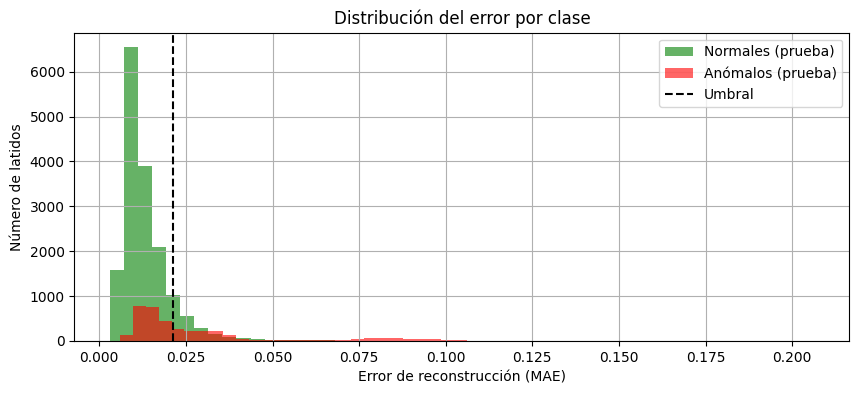

In [ ]:
recon_test_normal = autoencoder.predict(normal_test_data, verbose=0)
loss_test_normal = tf.keras.losses.mae(recon_test_normal, normal_test_data).numpy()

recon_test_anom = autoencoder.predict(anomalous_test_data, verbose=0)
loss_test_anom = tf.keras.losses.mae(recon_test_anom, anomalous_test_data).numpy()

plt.figure(figsize=(10, 4))
plt.hist(loss_test_normal, bins=50, alpha=0.6, label='Normales (prueba)', color='green')
plt.hist(loss_test_anom, bins=50, alpha=0.6, label='Anómalos (prueba)', color='red')
plt.axvline(threshold, color='black', linestyle='--', label='Umbral')
plt.xlabel("Error de reconstrucción (MAE)")
plt.ylabel("Número de latidos")
plt.title("Distribución del error por clase")
plt.legend()
plt.grid(True)
plt.show()

### Paso 19. Clasificar los latidos de prueba

Un latido se clasifica como **anómalo (1)** si su error supera el umbral, y como **normal (0)** en caso contrario.

> **Atención:** aquí la convención es distinta a la del notebook original. Ahora `1` significa **anómalo**, por lo que la predicción es `error > umbral`.

In [ ]:
def predecir_anomalia(modelo, datos, umbral):
    reconstrucciones = modelo.predict(datos, verbose=0)
    error = tf.keras.losses.mae(reconstrucciones, datos).numpy()
    return (error > umbral).astype(int), error

# Conjunto de prueba completo: normales y anómalos
test_data_completo = np.concatenate([normal_test_data, anomalous_test_data])
test_labels_completo = np.concatenate([
    np.zeros(len(normal_test_data), dtype=int),
    np.ones(len(anomalous_test_data), dtype=int)])

preds, test_loss = predecir_anomalia(autoencoder, test_data_completo, threshold)
print("Latidos de prueba evaluados:", len(preds))

Latidos de prueba evaluados: 19991


### Paso 20. Calcular las métricas

- **Accuracy:** proporción de aciertos totales.
- **Precisión:** de los latidos marcados como anómalos, cuántos realmente lo son.
- **Recall (sensibilidad):** de los anómalos reales, cuántos fueron detectados. En un contexto clínico suele ser la métrica más importante.
- **F1:** equilibrio entre precisión y recall.

In [ ]:
def imprimir_metricas(y_true, y_pred):
    print("Accuracy  = {:.3f}".format(accuracy_score(y_true, y_pred)))
    print("Precisión = {:.3f}".format(precision_score(y_true, y_pred, zero_division=0)))
    print("Recall    = {:.3f}".format(recall_score(y_true, y_pred, zero_division=0)))
    print("F1        = {:.3f}".format(f1_score(y_true, y_pred, zero_division=0)))

imprimir_metricas(test_labels_completo, preds)

Accuracy  = 0.811
Precisión = 0.473
Recall    = 0.416
F1        = 0.443


### Paso 21. Matriz de confusión

Muestra cuántos latidos se clasificaron correctamente y cuántos se confundieron.

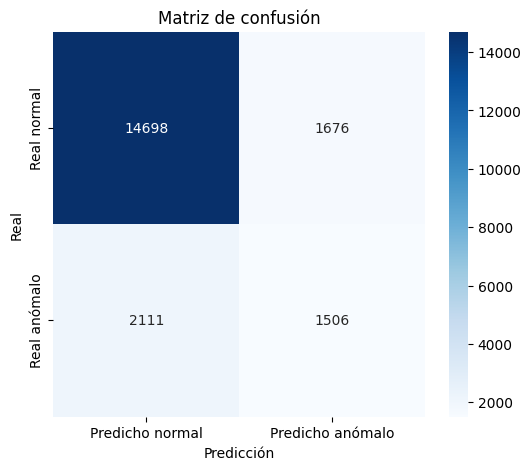

In [ ]:
cm = confusion_matrix(test_labels_completo, preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicho normal", "Predicho anómalo"],
            yticklabels=["Real normal", "Real anómalo"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión")
plt.show()

### Paso 22. Curva ROC y AUC

La curva ROC muestra el compromiso entre detectar anomalías y generar falsas alarmas para **todos los umbrales posibles**. El AUC resume esa curva: 1 es un clasificador perfecto y 0.5 equivale a adivinar al azar.

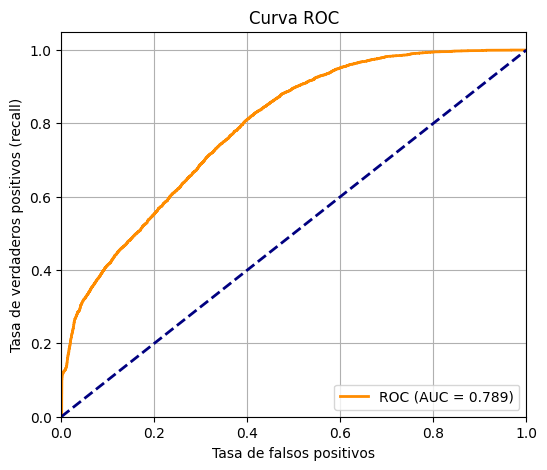

AUC = 0.7885


In [ ]:
fpr, tpr, _ = roc_curve(test_labels_completo, test_loss)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("AUC =", round(roc_auc, 4))

### Paso 23. Aplicar el detector a todo el registro

Finalmente, aplicamos el modelo a **todos** los latidos del registro y marcamos en rojo los que detecta como anómalos sobre la señal original. Mostramos los primeros 60 segundos.

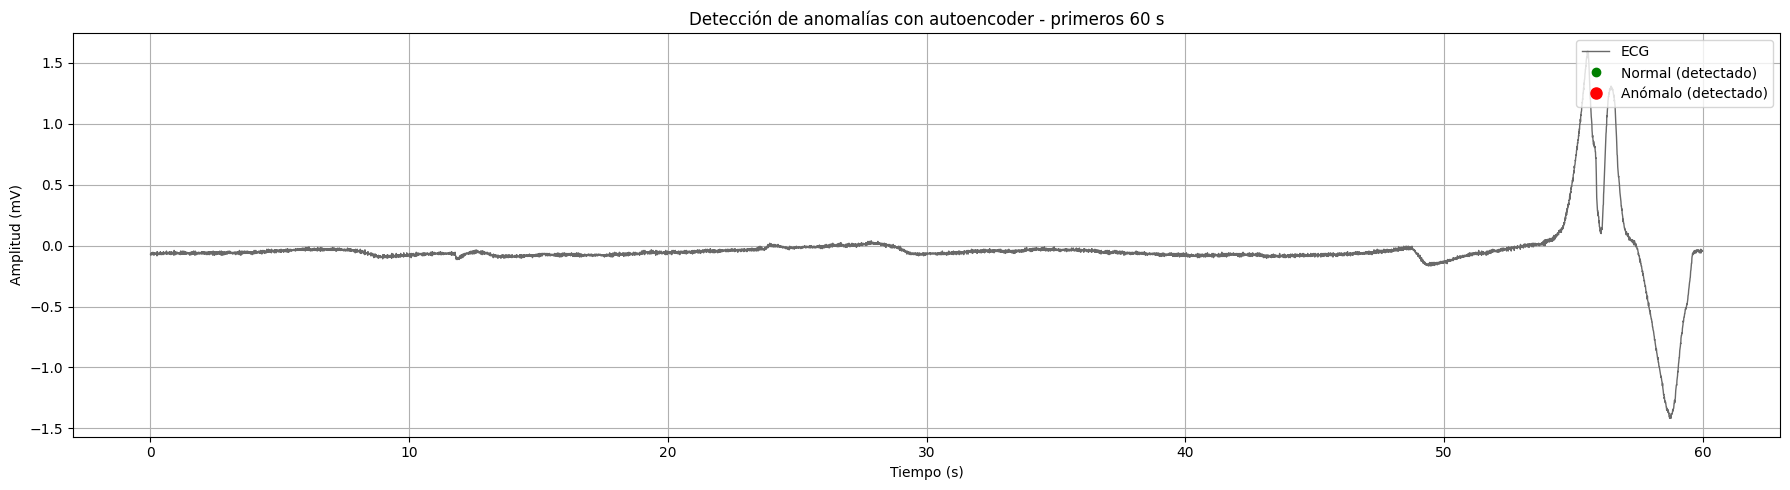

Latidos anómalos detectados en todo el registro: 16026 de 99954


In [ ]:
loss_all = tf.keras.losses.mae(autoencoder.predict(X_all_s, verbose=0), X_all_s).numpy()
pred_all = (loss_all > threshold)

segundos = 60
fin = min(len(signal), int(segundos * fs))
tiempo = np.arange(fin) / fs

plt.figure(figsize=(18, 5))
plt.plot(tiempo, signal[:fin], color='dimgray', linewidth=1, label='ECG')

mask_ventana = positions < fin
pos_ventana = positions[mask_ventana]
pred_ventana = pred_all[mask_ventana]

# Latidos normales detectados como tales
plt.plot(pos_ventana[~pred_ventana] / fs, signal[pos_ventana[~pred_ventana]],
         'o', color='green', markersize=6, label='Normal (detectado)')
# Latidos marcados como anómalos por el autoencoder
plt.plot(pos_ventana[pred_ventana] / fs, signal[pos_ventana[pred_ventana]],
         'o', color='red', markersize=8, label='Anómalo (detectado)')

plt.title(f'Detección de anomalías con autoencoder - primeros {segundos} s')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Latidos anómalos detectados en todo el registro:", int(pred_all.sum()), "de", len(pred_all))

## Parte 5. Ejercicios para la clase

1. **Cambie el umbral.** En lugar de `media + 1 σ`, use el percentil 95 del error de entrenamiento: `threshold = np.percentile(train_loss, 95)`. Vuelva a ejecutar los pasos 19 a 22. ¿Sube o baja el recall? ¿Y la precisión?

2. **Cambie la definición de anomalía.** En el Paso 6, considere anómalos también los símbolos `L` y `R`. ¿Mejora o empeora la detección?

3. **Cambie el tamaño del cuello de botella.** En el Paso 10, reduzca la última capa del encoder de 8 a 2 neuronas. ¿Cómo cambia la reconstrucción de los latidos normales?

4. **Analice los falsos negativos.** Grafique algunos latidos anómalos que el modelo no detectó (error por debajo del umbral). ¿Qué tienen en común?

5. **Discusión:** ¿por qué un autoencoder entrenado solo con normales puede ser útil cuando hay muy pocos ejemplos anómalos etiquetados? ¿Qué riesgos tiene usar sus resultados para diagnóstico?

## Limitaciones

Esta práctica tiene fines didácticos. Las etiquetas provienen de anotaciones de un solo registro, el umbral se fija de forma sencilla y no se valida con otros pacientes. Cualquier aplicación clínica requiere validación rigurosa y la supervisión de profesionales de la salud.